# Lab 26: Response Curves and Marginal Returns

This lab fits the reference Bayesian MMM from Lab 15, then turns every posterior draw into a response curve for each channel: expected weekly contribution as a function of the channel's budget.
Each curve is drawn with its 90 per cent band across draws and with the budgets Sedge has actually run marked beneath it, as Chapter 26 asks.
At current spend the lab reads off both the average return (contribution divided by spend) and the marginal return (the slope of the curve), each as a distribution.
It accompanies Chapter 26 of the book Marketing Mix Modelling.

In [1]:
import arviz as az
import matplotlib.pyplot as plt
import numpy as np
import pymc as pm

from mmm_book import RANDOM_SEED
from mmm_book.adstock import geometric_adstock
from mmm_book.plotting import mmm_style
from mmm_book.reference import (
    DRIVER_COL,
    REVENUE_SCALE,
    national_aggregate,
    reference_model,
    saturation_means,
)
from mmm_book.saturation import hill_saturation
from mmm_book.sedge import (
    ADSTOCK_ALPHA,
    CHANNELS,
    HALF_MULT,
    HILL_SLOPE,
    generate_sedge,
)

mmm_style()

SPEND_COL = {
    "tv": "tv_spend",
    "search": "search_spend",
    "meta": "meta_spend",
    "youtube": "youtube_spend",
    "ooh": "ooh_spend",
}

## Fitting the reference model

This reuses the shared national-aggregate reference model from `mmm_book.reference`, the model Lab 15 builds with the priors Lab 17 chooses.
Sampling uses the settings every lab uses (four chains of 1,000 draws after 1,000 warm-up steps, target acceptance 0.95), and the cell checks the fit before anything is read from it.

In [2]:
df = generate_sedge()
nat = national_aggregate(df)

with reference_model(nat):
    idata = pm.sample(
        draws=1000,
        tune=1000,
        chains=4,
        cores=1,
        target_accept=0.95,
        random_seed=RANDOM_SEED,
        progressbar=False,
    )

n_divergent = int(idata.sample_stats["diverging"].sum())
r_hat = float(az.summary(idata, kind="diagnostics")["r_hat"].max())
print(f"divergent transitions: {n_divergent}, largest r_hat: {r_hat:.3f}")

beta_draws = {ch: idata.posterior[f"beta_{ch}"].to_numpy().reshape(-1) for ch in CHANNELS}

Initializing NUTS using jitter+adapt_diag...


Sequential sampling (4 chains in 1 job)


NUTS: [intercept, trend, season_a, season_b, omega_launch, delta_promo, gamma_log_price, gamma_distribution, gamma_stock, gamma_temperature, gamma_rainfall, gamma_category, beta_tv, beta_search, beta_meta, beta_youtube, beta_ooh, sigma]


Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 26 seconds.


divergent transitions: 0, largest r_hat: 1.004


## Building the response curve

Chapter 26 defines the curve $R(x)$ by scaling the channel's historical weekly plan: every week's spend is multiplied by the same factor so that the budget is $x$, the result passes through the channel's adstock and saturation, and the weekly contributions are averaged.
Scaling the plan keeps its flighting, so Television stays concentrated around the spring races and Christmas at any budget.
The lab measures $x$ as average weekly spend, with Television's GRPs valued at `TV_COST_PER_GRP` (400 pounds per GRP, as Chapter 14 does) so that every channel is on the same footing.
Paid Search is driven by its generic impressions, which scale with Search spend, while its ROAS is quoted on total Search spend.

The half-saturation point stays where the model fitted it, `HALF_MULT` ($k_m$) times the historical average adstocked activity, because it is a property of the channel's response, not of any one budget.
In this model the curve's shape is fixed, so it is the same for every draw, `shape(ch, factor)`.
Each draw's beta scales it, and since the feature was divided by its historical mean, the contribution at the current plan is exactly that draw's beta.

In [3]:
hill_mean = saturation_means(nat)
driver = {ch: nat[DRIVER_COL[ch]].to_numpy(dtype=float) for ch in CHANNELS}
half = {
    ch: HALF_MULT[ch]
    * geometric_adstock(driver[ch], alpha=ADSTOCK_ALPHA[ch], normalize=True).mean()
    for ch in CHANNELS
}
current = {ch: float(nat[SPEND_COL[ch]].mean()) for ch in CHANNELS}


def shape(ch, factor):
    """Average Hill value of the historical plan scaled by `factor`, on the beta's scale."""
    adstocked = geometric_adstock(driver[ch] * factor, alpha=ADSTOCK_ALPHA[ch], normalize=True)
    return hill_saturation(adstocked, half=half[ch], slope=HILL_SLOPE[ch]).mean() / hill_mean[ch]


def curve_draws(ch, spend):
    """Weekly contribution (GBP) at average weekly spend `spend`, one value per posterior draw."""
    return beta_draws[ch] * shape(ch, spend / current[ch]) * REVENUE_SCALE

## Average and marginal return at current spend

Average return is contribution at current spend divided by that spend: the channel's ROAS.
Marginal return is the extra contribution from a 1 per cent rise in every week's spend, divided by the extra spend, the way the case study computes it (Chapter 14).
Both are worked out draw by draw, so each arrives as a distribution; the table gives the posterior mean and the 90 per cent interval.
The two agree only where the curve is a straight line through the origin; where it has started to bend over, average return overstates what the next pound buys.

In [4]:
average = {}
marginal = {}
for ch in CHANNELS:
    now = curve_draws(ch, current[ch])
    up = curve_draws(ch, current[ch] * 1.01)
    average[ch] = now / current[ch]
    marginal[ch] = (up - now) / (current[ch] * 0.01)


def fmt(draws):
    lo, hi = np.percentile(draws, [5, 95])
    return f"{draws.mean():5.2f} ({lo:.2f} to {hi:.2f})"


print(f"{'channel':<9}{'average return':>24}{'marginal return':>24}")
for ch in CHANNELS:
    print(f"{ch:<9}{fmt(average[ch]):>24}{fmt(marginal[ch]):>24}")

channel            average return         marginal return
tv            2.39 (2.18 to 2.60)     2.10 (1.91 to 2.28)
search        3.10 (0.74 to 5.54)     1.62 (0.39 to 2.90)
meta          3.07 (1.61 to 4.34)     1.58 (0.83 to 2.23)
youtube       1.02 (0.09 to 2.45)     0.92 (0.08 to 2.20)
ooh           1.50 (0.15 to 3.34)     1.47 (0.14 to 3.27)


## The curves, with their uncertainty and their support

Each panel draws the posterior mean curve and its 90 per cent band, marks current spend with the tangent whose slope is the mean marginal return, and shades the range of budgets Sedge has actually run: the lowest to the highest of the three years' average weekly spend.
Outside that range the curve is extrapolation.

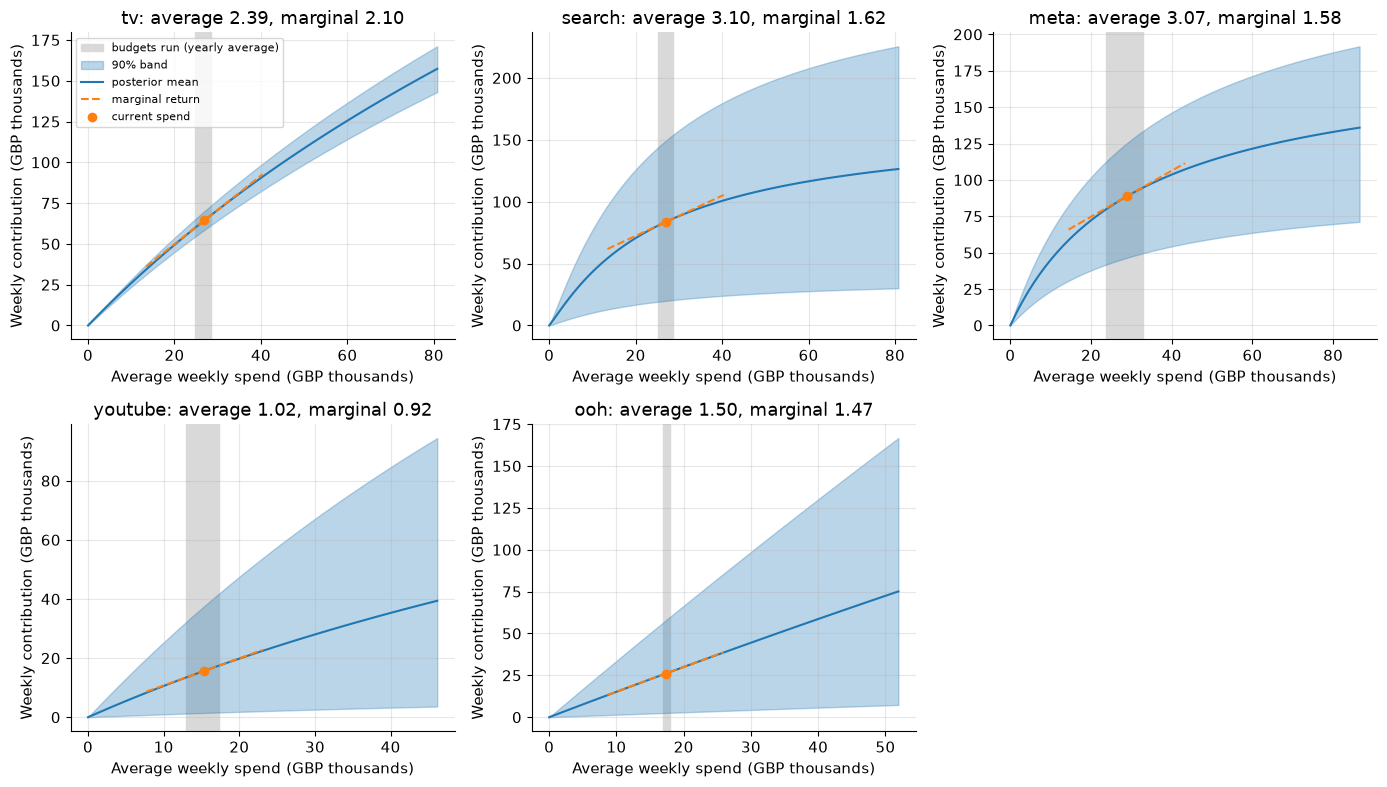

In [5]:
year = nat["week"].to_numpy() // 52
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
axes = axes.flatten()

for ax, ch in zip(axes, CHANNELS, strict=False):
    grid = np.linspace(0, current[ch] * 3, 61)
    draws = np.array([curve_draws(ch, x) for x in grid]) / 1e3
    lo, hi = np.percentile(draws, [5, 95], axis=1)
    yearly = nat.groupby(year)[SPEND_COL[ch]].mean()

    ax.axvspan(
        yearly.min() / 1e3, yearly.max() / 1e3, color="0.85", label="budgets run (yearly average)"
    )
    ax.fill_between(grid / 1e3, lo, hi, color="C0", alpha=0.3, label="90% band")
    ax.plot(grid / 1e3, draws.mean(axis=1), color="C0", label="posterior mean")

    now = curve_draws(ch, current[ch]).mean() / 1e3
    tangent_x = np.array([current[ch] * 0.5, current[ch] * 1.5])
    tangent_y = now + marginal[ch].mean() / 1e3 * (tangent_x - current[ch])
    ax.plot(tangent_x / 1e3, tangent_y, "--", color="C1", label="marginal return")
    ax.scatter([current[ch] / 1e3], [now], color="C1", zorder=5, label="current spend")

    ax.set_title(f"{ch}: average {average[ch].mean():.2f}, marginal {marginal[ch].mean():.2f}")
    ax.set_xlabel("Average weekly spend (GBP thousands)")
    ax.set_ylabel("Weekly contribution (GBP thousands)")

axes[0].legend(fontsize=8, loc="upper left")
axes[-1].axis("off")
fig.tight_layout()

## Takeaway

Every channel's marginal return sits below its average return at current spend, because every curve here is concave: each extra pound buys less than the pounds before it.
How far below depends on where the channel sits on its curve.
Television, YouTube and OOH are still on the early, nearly straight part of theirs, so marginal is close to average (Television 2.10 against 2.39, OOH 1.47 against 1.50).
Search and Meta are well into diminishing returns, with a marginal return about half their average (1.62 against 3.10, and 1.58 against 3.07).
The intervals are as important as the means: Search's marginal return could be anywhere from 0.39 to 2.90, and YouTube's and OOH's from close to zero to above 2, so on this national fit only Television's position against Sedge's 2.0x break-even is clear.

The bands deserve a warning of their own.
Chapter 26 expects a band to widen beyond the budgets a channel has actually run, because there the curve rests on its functional form and priors, and says a band that does not widen may be overconfident.
Here every draw shares the same fixed shape and differs only in height, so each band is a constant proportion of its curve and widens beyond support only because the curve rises.
The uncertainty about the shape, which matters most far from the shaded range, is missing because this model fixes the adstock and saturation at their true values.
The case-study model estimates them, so each of its posterior draws has its own curve shape and its bands carry that uncertainty too (`notebooks/case_study/37_average_to_next_pound.ipynb` draws them).

Average return answers 'was this channel worth what we spent on it', a backward-looking question about all the spend so far, including the earlier, less saturated pounds.
Marginal return answers 'what would the next pound buy'.
It is marginal return, with its uncertainty, that should drive whether to spend more or less on a channel, and Lab 27's budget optimisation is built around comparing channels' marginal returns.